# Netflix Content Analysis – What Makes Content Popular?

**Author:** Italo
**GitHub repository:** https://github.com/Italoomoura/Netflix_Project_Assignment

**Challenge 1:** What makes content popular on Netflix?
**Business question:** What characteristics are most common among the titles that viewers watch the most and rate the highest?

**Dataset** (`data/raw/`): `movies.csv` (24 titles), `users.csv` (20 viewers) and `watch_history.csv` (120 viewing records with rating and date).

**Popularity definition:** measured with viewer behavior from `watch_history`: number of views, unique viewers and average rating per title. A title is *popular* if it is in the top 25% by views. See `docs/project_plan.md` for the full scope, sprint goal and risks.

**Notebook outline**
1. Load & Inspect Datasets
2. Clean & Merge Data
3. Exploratory Data Analysis (EDA)
4. Visualizations
5. Business Insights
6. Conclusions

**How to read this notebook:** every section starts with what is being done and why, and ends with an interpretation of the results. The notebook runs from top to bottom (`Kernel > Restart & Run All`) and needs the packages in `requirements.txt`.

## 1. Load & Inspect Datasets

In this section we load the three source tables (`movies`, `users`, `watch_history`) and check their shape, data types, missing values and duplicates before any cleaning.

### 1.1 Imports and configuration

In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

DATA_RAW = Path("../data/raw")

### 1.2 Load the datasets

In [2]:
movies = pd.read_csv(DATA_RAW / "movies.csv")
users = pd.read_csv(DATA_RAW / "users.csv")
watch_history = pd.read_csv(DATA_RAW / "watch_history.csv")

datasets = {"movies": movies, "users": users, "watch_history": watch_history}

for name, df in datasets.items():
    print(f"{name:<14} {df.shape[0]:>4} rows x {df.shape[1]} columns")

movies           24 rows x 7 columns
users            20 rows x 5 columns
watch_history   120 rows x 4 columns


### 1.3 Inspection helper
A small function so that every table is inspected in exactly the same way: preview, data types, missing values and duplicates.

In [3]:
def inspect_dataset(df, name, key_columns=None):
    """Print a standard inspection report for a DataFrame."""
    print(f"{'=' * 60}\n{name.upper()}  |  shape: {df.shape}\n{'=' * 60}")

    print("\nFirst rows:")
    display(df.head())

    print("Data types:")
    display(df.dtypes.rename("dtype").to_frame())

    nulls = df.isna().sum().rename("missing_values").to_frame()
    nulls["missing_%"] = (nulls["missing_values"] / len(df) * 100).round(2)
    print("Missing values:")
    display(nulls)

    print(f"Fully duplicated rows: {df.duplicated().sum()}")
    if key_columns:
        print(f"Duplicated {key_columns}: {df.duplicated(subset=key_columns).sum()}")

### 1.4 `movies`

In [4]:
inspect_dataset(movies, "movies", key_columns=["movie_id"])

MOVIES  |  shape: (24, 7)

First rows:


,movie_id,title,duration,release_year,genre,director,cast
0,1,The Last Signal,112,2018,Science Fiction,Mara Collins,Ethan Cole; Sofia Reyes
1,2,Neon Horizon,124,2021,Science Fiction,Daniel Kim,Lena Park; Marcus Reed
2,3,Orbit 9,98,2016,Science Fiction,Mara Collins,Noah Bennett; Ava Brooks
3,4,Silent Planet,135,2023,Science Fiction,Priya Shah,Sofia Reyes; Oliver Grant
4,5,Echoes of Tomorrow,107,2020,Science Fiction,Daniel Kim,Lena Park; Ethan Cole


Data types:


,dtype
movie_id,int64
title,str
duration,int64
release_year,int64
genre,str
director,str
cast,str


Missing values:


,missing_values,missing_%
movie_id,0,0.0
title,0,0.0
duration,0,0.0
release_year,0,0.0
genre,0,0.0
director,0,0.0
cast,0,0.0


Fully duplicated rows: 0
Duplicated ['movie_id']: 0


In [5]:
print("Duplicated titles:", movies["title"].duplicated().sum())
print("\nNumeric summary:")
display(movies[["duration", "release_year"]].describe())
print("Movies per genre:")
display(movies["genre"].value_counts().rename("titles").to_frame())

Duplicated titles: 0

Numeric summary:


,duration,release_year
count,24.000000,24.000000
mean,113.500000,2019.666667
std,12.507389,2.807856
min,95.000000,2015.000000
25%,103.750000,2017.750000
50%,112.500000,2020.000000
75%,122.500000,2022.000000
max,139.000000,2024.000000


Movies per genre:


,titles
genre,
Science Fiction,5
Thriller,4
Horror,3
Romance,3
Drama,3
Comedy,3
Adventure,3


### 1.5 `users`

In [6]:
inspect_dataset(users, "users", key_columns=["user_id"])

USERS  |  shape: (20, 5)

First rows:


,user_id,age,name,country,genre
0,101,19,Alex Morgan,Germany,Male
1,102,24,Beatriz Lima,Brazil,Female
2,103,31,Carlos Mendes,Portugal,Male
3,104,27,Diana Costa,Spain,Female
4,105,22,Ethan Wilson,United States,Male


Data types:


,dtype
user_id,int64
age,int64
name,str
country,str
genre,str


Missing values:


,missing_values,missing_%
user_id,0,0.0
age,0,0.0
name,0,0.0
country,0,0.0
genre,0,0.0


Fully duplicated rows: 0
Duplicated ['user_id']: 0


In [7]:
print("Numeric summary:")
display(users[["age"]].describe())
print("Values in column 'genre':", users["genre"].unique().tolist())
print("\nUsers per country:")
display(users["country"].value_counts().rename("users").to_frame())

Numeric summary:


,age
count,20.000000
mean,28.600000
std,7.659875
min,18.000000
25%,22.750000
50%,27.500000
75%,33.500000
max,45.000000


Values in column 'genre': ['Male', 'Female']

Users per country:


,users
country,
Germany,4
Brazil,4
Portugal,3
Spain,2
United States,2
United Kingdom,2
Poland,1
Canada,1
Italy,1


### 1.6 `watch_history`

In [8]:
inspect_dataset(watch_history, "watch_history")

WATCH_HISTORY  |  shape: (120, 4)

First rows:


,movie_id,user_id,rating,date
0,6,101,2,2025-01-05
1,14,102,5,2025-01-10
2,8,103,4,2025-01-15
3,1,104,4,2025-01-20
4,12,105,4,2025-01-25


Data types:


,dtype
movie_id,int64
user_id,int64
rating,int64
date,str


Missing values:


,missing_values,missing_%
movie_id,0,0.0
user_id,0,0.0
rating,0,0.0
date,0,0.0


Fully duplicated rows: 0


In [9]:
print("Rating distribution:")
display(watch_history["rating"].value_counts().sort_index().rename("records").to_frame())

print("Date range (text column, not yet converted):",
      watch_history["date"].min(), "to", watch_history["date"].max())

pair_counts = watch_history.groupby(["user_id", "movie_id"]).size()
print("\nUser-movie pairs that appear more than once:", (pair_counts > 1).sum())
print("Extra records caused by repeated pairs:", watch_history.duplicated(subset=["user_id", "movie_id"]).sum())
print("Max times the same user watched the same movie:", pair_counts.max())
print("Same user + movie + date (true duplicates):",
      watch_history.duplicated(subset=["user_id", "movie_id", "date"]).sum())

Rating distribution:


,records
rating,
2,4
3,30
4,44
5,42


Date range (text column, not yet converted): 2025-01-05 to 2026-01-06

User-movie pairs that appear more than once: 32
Extra records caused by repeated pairs: 40
Max times the same user watched the same movie: 4
Same user + movie + date (true duplicates): 0


### 1.7 Referential integrity between tables

In [10]:
orphan_movies = set(watch_history["movie_id"]) - set(movies["movie_id"])
orphan_users = set(watch_history["user_id"]) - set(users["user_id"])
unwatched_movies = set(movies["movie_id"]) - set(watch_history["movie_id"])
inactive_users = set(users["user_id"]) - set(watch_history["user_id"])

print("movie_ids in watch_history missing from movies:", orphan_movies or "none")
print("user_ids in watch_history missing from users:", orphan_users or "none")
print("Movies never watched:", unwatched_movies or "none")
print("Users with no watch records:", inactive_users or "none")

movie_ids in watch_history missing from movies: none
user_ids in watch_history missing from users: none
Movies never watched: none
Users with no watch records: none


### 1.8 Observations

- **Shapes:** `movies` has 24 rows, `users` 20 rows and `watch_history` 120 rows. This is a small sample, so findings should be treated as indications, not statistical proof.
- **Missing values:** none in any of the three tables, so no imputation is needed.
- **Keys:** `movie_id` and `user_id` are unique in their own tables, and every key in `watch_history` exists in `movies` and `users`. Every movie was watched at least once and every user has watch records.
- **Fully duplicated rows:** none.
- **Repeated user–movie pairs:** 32 pairs appear more than once (40 extra records, up to 4 times for the same pair). The dates always differ, so they are treated as **re-watches**, and each record counts as one view.
- **Column naming issue:** in `users`, the column `genre` actually contains gender (Male/Female). It will be renamed to `gender` during cleaning to avoid confusion with `movies.genre`.
- **Data types:** `date` in `watch_history` is stored as text and must be converted to datetime.
- **Value ranges look plausible:** ratings 2–5, ages 18–45, durations 95–139 minutes, release years 2015–2024.

## 2. Clean & Merge Data

Based on the inspection in section 1, this section:
1. Works on copies so the raw data stays untouched.
2. Handles missing values (verifying that none exist).
3. Fixes column naming and standardizes text, duration and date formats.
4. Parses the multi-value field `cast`.
5. Merges the three tables into one analysis-ready dataset and validates the result.

### 2.1 Work on copies

In [11]:
movies_clean = movies.copy()
users_clean = users.copy()
watch_clean = watch_history.copy()

### 2.2 Missing values
Section 1 found no missing values. We make that a hard check, so the notebook fails loudly if the raw data ever changes, and we also look for empty strings, which `isna()` does not catch.

In [12]:
for name, df in {"movies": movies_clean, "users": users_clean, "watch_history": watch_clean}.items():
    total_nulls = int(df.isna().sum().sum())
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    empty_strings = int((df[text_cols].apply(lambda col: col.str.strip() == "")).sum().sum())
    print(f"{name:<14} nulls: {total_nulls} | empty strings: {empty_strings}")
    assert total_nulls == 0 and empty_strings == 0, f"Unexpected missing data in {name}"

print("\nNo missing values: no imputation or row removal is needed.")

movies         nulls: 0 | empty strings: 0
users          nulls: 0 | empty strings: 0
watch_history  nulls: 0 | empty strings: 0

No missing values: no imputation or row removal is needed.


### 2.3 Column naming and text standardization
- `users.genre` holds gender, so it is renamed to `gender`.
- `users.country` is renamed to `user_country` to make clear it is the **viewer's** country (movies have no country).
- Leading/trailing spaces are stripped from all text columns.

In [13]:
users_clean = users_clean.rename(columns={"genre": "gender", "country": "user_country"})

for df in (movies_clean, users_clean):
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()

print("users columns:", users_clean.columns.tolist())
print("gender values:", users_clean["gender"].unique().tolist())

users columns: ['user_id', 'age', 'name', 'user_country', 'gender']
gender values: ['Male', 'Female']


### 2.4 Standardize duration
`duration` is already numeric (minutes). We make this explicit in the column name, confirm the type and check the range.

In [14]:
movies_clean = movies_clean.rename(columns={"duration": "duration_min"})
movies_clean["duration_min"] = movies_clean["duration_min"].astype(int)

print(movies_clean["duration_min"].describe()[["min", "max", "mean"]].round(1).to_dict())
assert movies_clean["duration_min"].between(30, 300).all(), "Duration outside a plausible range"

{'min': 95.0, 'max': 139.0, 'mean': 113.5}


### 2.5 Standardize dates
`date` is stored as text (`YYYY-MM-DD`). It is converted to a real datetime, renamed `watch_date`, and a `watch_month` column is added for trend analysis later.

In [15]:
watch_clean["watch_date"] = pd.to_datetime(watch_clean["date"], format="%Y-%m-%d", errors="raise")
watch_clean = watch_clean.drop(columns="date")
watch_clean["watch_month"] = watch_clean["watch_date"].dt.to_period("M").astype(str)

print(watch_clean["watch_date"].dtype)
print("Period:", watch_clean["watch_date"].min().date(), "to", watch_clean["watch_date"].max().date())
print("Months covered:", watch_clean["watch_month"].nunique())

datetime64[us]
Period: 2025-01-05 to 2026-01-06
Months covered: 13


### 2.6 Parse multi-value fields
`cast` stores several actors in one cell, separated by `;`. Other columns (`genre`, `director`) hold a single value per movie.

We keep the original `cast` column and also create a **long table** `movie_cast` (one row per movie–actor pair), which is the right shape for counting how often each actor appears.

In [16]:
movies_clean["cast_list"] = movies_clean["cast"].str.split(";").apply(lambda names: [n.strip() for n in names])
movies_clean["cast_size"] = movies_clean["cast_list"].str.len()

movie_cast = (
    movies_clean[["movie_id", "cast_list"]]
    .explode("cast_list")
    .rename(columns={"cast_list": "actor"})
    .reset_index(drop=True)
)

print("Cast size per movie:", movies_clean["cast_size"].value_counts().to_dict())
print("Movie–actor rows:", len(movie_cast), "| distinct actors:", movie_cast["actor"].nunique())
display(movie_cast.head())

Cast size per movie: {2: 24}
Movie–actor rows: 48 | distinct actors: 8


,movie_id,actor
0,1,Ethan Cole
1,1,Sofia Reyes
2,2,Lena Park
3,2,Marcus Reed
4,3,Noah Bennett


### 2.7 Merge the tables
`watch_history` is the central (fact) table: each row is one view. Movie and user attributes are attached with **left joins**, validated as many-to-one, so the number of rows must stay at 120.

In [17]:
movie_columns = ["movie_id", "title", "genre", "duration_min", "release_year", "director", "cast"]
user_columns = ["user_id", "age", "gender", "user_country"]

merged = (
    watch_clean
    .merge(movies_clean[movie_columns], on="movie_id", how="left", validate="many_to_one")
    .merge(users_clean[user_columns], on="user_id", how="left", validate="many_to_one")
)

column_order = [
    "user_id", "movie_id", "title", "genre", "duration_min", "release_year", "director", "cast",
    "rating", "watch_date", "watch_month", "age", "gender", "user_country",
]
merged = merged[column_order].sort_values("watch_date").reset_index(drop=True)

print("Merged shape:", merged.shape)
display(merged.head())

Merged shape: (120, 14)


,user_id,movie_id,title,genre,duration_min,release_year,director,cast,rating,watch_date,watch_month,age,gender,user_country
0,101,6,Midnight Runaway,Thriller,101,2017,Lucas Meyer,Mia Foster; Noah Bennett,2,2025-01-05,2025-01,19,Male,Germany
1,102,14,Letters in December,Romance,114,2020,Isabel Costa,Mia Foster; Ethan Cole,5,2025-01-10,2025-01,24,Female,Brazil
2,103,8,Cold Evidence,Thriller,109,2019,Lucas Meyer,Marcus Reed; Mia Foster,4,2025-01-15,2025-01,31,Male,Portugal
3,104,1,The Last Signal,Science Fiction,112,2018,Mara Collins,Ethan Cole; Sofia Reyes,4,2025-01-20,2025-01,27,Female,Spain
4,105,12,Red Harvest,Horror,116,2018,Priya Shah,Marcus Reed; Lena Park,4,2025-01-25,2025-01,22,Male,United States


### 2.8 Validate the merged dataset

In [18]:
assert len(merged) == len(watch_history), "Row count changed during merge"
assert merged.isna().sum().sum() == 0, "Nulls introduced by merge"
assert merged["rating"].between(1, 5).all(), "Rating outside 1-5"
assert set(merged["movie_id"]) == set(movies["movie_id"]), "Some movies were lost"
assert set(merged["user_id"]) == set(users["user_id"]), "Some users were lost"
assert (merged.groupby("movie_id").size() == watch_history.groupby("movie_id").size()).all(), "Views per movie changed"

print("All validation checks passed.")
print("\nFinal data types:")
display(merged.dtypes.rename("dtype").to_frame())

All validation checks passed.

Final data types:


,dtype
user_id,int64
movie_id,int64
title,str
genre,str
duration_min,int64
release_year,int64
director,str
cast,str
rating,int64
watch_date,datetime64[us]


### 2.9 Save processed data

In [19]:
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

merged.to_csv(PROCESSED / "merged_watch_data.csv", index=False)
movie_cast.to_csv(PROCESSED / "movie_cast.csv", index=False)

print("Saved:", sorted(p.name for p in PROCESSED.glob("*.csv")))

Saved: ['merged_watch_data.csv', 'movie_cast.csv']


### 2.10 Summary of cleaning decisions

| Issue | Decision |
|---|---|
| Missing values | None found (verified with a check); no imputation or removal |
| `users.genre` contains gender | Renamed to `gender` |
| `users.country` is the viewer's country | Renamed to `user_country` |
| `duration` | Already numeric; renamed `duration_min` (minutes) and range-checked |
| `date` stored as text | Converted to datetime (`watch_date`); added `watch_month` |
| Multi-value `cast` | Kept original column and created long table `movie_cast` (one row per movie–actor) |
| Repeated user–movie pairs | Kept: they have different dates, so each record is one view (re-watch) |
| Merge | `watch_history` as base table, left joins validated many-to-one; 120 rows preserved |

**Output:** `data/processed/merged_watch_data.csv` (120 rows × 14 columns) and `data/processed/movie_cast.csv`.

## 3. Exploratory Data Analysis (EDA)

Goal: understand how viewing volume and ratings are distributed and how they relate to the key title characteristics (genre, duration, release year, director, cast) and to the viewer profile.

Since `watch_history` has 120 records for only 24 titles, most comparisons are made at **title level** (one row per movie) and, when groups have different sizes (genres, actors), **normalized per title** to avoid catalog-size bias. Tables are used here; charts come in the Visualizations section.

### 3.1 Title-level summary
One row per movie with its views, unique viewers and average rating. A title is flagged as **popular** if its views are in the top 25% (as defined in the project scope).

In [20]:
from scipy import stats

title_stats = (
    merged.groupby(["movie_id", "title", "genre", "duration_min", "release_year", "director"], as_index=False)
    .agg(views=("rating", "size"), unique_viewers=("user_id", "nunique"), avg_rating=("rating", "mean"))
)
title_stats["avg_rating"] = title_stats["avg_rating"].round(2)

POPULAR_CUTOFF = title_stats["views"].quantile(0.75)
title_stats["is_popular"] = title_stats["views"] >= POPULAR_CUTOFF

print(f"Popular = views >= {POPULAR_CUTOFF} -> {title_stats['is_popular'].sum()} of {len(title_stats)} titles")
display(title_stats.sort_values(["views", "avg_rating"], ascending=False).reset_index(drop=True))

Popular = views >= 6.25 -> 6 of 24 titles


,movie_id,title,genre,duration_min,release_year,director,views,unique_viewers,avg_rating,is_popular
0,1,The Last Signal,Science Fiction,112,2018,Mara Collins,10,4,4.00,True
1,24,Beyond the Ridge,Adventure,139,2023,Elena Rossi,8,5,4.12,True
2,4,Silent Planet,Science Fiction,135,2023,Priya Shah,8,5,4.00,True
3,17,The Long Way Home,Drama,131,2022,Elena Rossi,8,5,3.88,True
4,13,A Summer Apart,Romance,108,2016,Isabel Costa,7,4,4.00,True
5,2,Neon Horizon,Science Fiction,124,2021,Daniel Kim,7,4,3.86,True
6,23,The Forgotten Map,Adventure,118,2020,Mara Collins,6,4,4.67,False
7,8,Cold Evidence,Thriller,109,2019,Lucas Meyer,6,4,4.50,False
8,19,Final Whistle,Comedy,106,2015,Lucas Meyer,6,4,3.83,False
9,9,No Way Back,Thriller,128,2024,Elena Rossi,5,5,4.40,False


### 3.2 Rating distribution

In [21]:
rating_dist = merged["rating"].value_counts().sort_index().rename("records").to_frame()
rating_dist["share_%"] = (rating_dist["records"] / len(merged) * 100).round(1)
display(rating_dist)

print("Overall rating: mean = %.2f | median = %.1f | std = %.2f" % (
    merged["rating"].mean(), merged["rating"].median(), merged["rating"].std()))
print("Share of ratings >= 4: %.1f%%" % ((merged["rating"] >= 4).mean() * 100))

print("\nAverage rating given per user:")
display(merged.groupby("user_id")["rating"].mean().describe().round(2).to_frame("avg_rating_per_user"))

,records,share_%
rating,,
2,4,3.3
3,30,25.0
4,44,36.7
5,42,35.0


Overall rating: mean = 4.03 | median = 4.0 | std = 0.86
Share of ratings >= 4: 71.7%

Average rating given per user:


,avg_rating_per_user
count,20.00
mean,4.03
std,0.22
min,3.67
25%,3.83
50%,4.00
75%,4.17
max,4.33


**Interpretation:** ratings are concentrated in the upper range: 71.7% of ratings are 4 or 5 and the mean is 4.03. Viewers are generally satisfied and each user's average rating varies little (3.67 to 4.33), so differences between titles will be small and must be read with care.

### 3.3 Viewing volume
Every user has exactly 6 records, so volume differences come from **titles**, not from heavier users. We look at the distribution of views per title and the monthly volume.

In [22]:
print("Views per title:")
display(title_stats["views"].describe().round(2).to_frame("views_per_title"))

print("How many titles have N views:")
display(title_stats["views"].value_counts().sort_index().rename("titles").to_frame())

print("Records per user:", merged.groupby("user_id").size().unique().tolist())

monthly = merged.groupby("watch_month").agg(views=("rating", "size"), avg_rating=("rating", "mean")).round(2)
print("\nMonthly volume (2026-01 only covers the first days of the month):")
display(monthly)

Views per title:


,views_per_title
count,24.00
mean,5.00
std,2.25
min,1.00
25%,3.00
50%,5.00
75%,6.25
max,10.00


How many titles have N views:


,titles
views,
1,1
2,2
3,4
4,3
5,5
6,3
7,2
8,3
10,1


Records per user: [6]

Monthly volume (2026-01 only covers the first days of the month):


,views,avg_rating
watch_month,,
2025-01,8,4.00
2025-02,9,4.22
2025-03,10,4.20
2025-04,11,3.73
2025-05,9,4.11
2025-06,10,4.00
2025-07,10,4.00
2025-08,11,4.09
2025-09,10,4.10


**Interpretation:** views per title range from 1 to 10 (mean and median of 5), and six titles have 7 or more views. Monthly volume is steady at 8 to 11 views per month throughout 2025, with no clear seasonality; 2026-01 has only 2 views because the data ends on January 6.

### 3.4 Genre
Genres have different numbers of titles, so views are normalized as **views per title**. Average duration is shown too, because it may be related to genre.

In [23]:
genre_stats = (
    merged.groupby("genre")
    .agg(views=("rating", "size"), unique_viewers=("user_id", "nunique"), avg_rating=("rating", "mean"))
)
genre_stats["titles"] = movies_clean["genre"].value_counts()
genre_stats["views_per_title"] = genre_stats["views"] / genre_stats["titles"]
genre_stats["avg_duration_min"] = title_stats.groupby("genre")["duration_min"].mean()
genre_stats["popular_titles"] = title_stats.groupby("genre")["is_popular"].sum()

display(genre_stats.sort_values("views_per_title", ascending=False).round(2)[
    ["titles", "views", "views_per_title", "avg_rating", "avg_duration_min", "popular_titles"]
])

,titles,views,views_per_title,avg_rating,avg_duration_min,popular_titles
genre,,,,,,
Science Fiction,5,29,5.80,3.93,115.20,3
Adventure,3,17,5.67,4.35,127.67,1
Drama,3,16,5.33,3.88,119.00,1
Thriller,4,20,5.00,4.30,114.25,0
Romance,3,14,4.67,4.07,107.00,1
Comedy,3,13,4.33,3.92,105.33,0
Horror,3,11,3.67,3.64,104.67,0


**Interpretation:** Science Fiction has the highest views per title (5.8) and 3 of the 6 popular titles, Adventure has the best average rating, and Horror trails on both. The genres with the most views per title are also the ones with the longest average duration (Adventure 128 min, Drama 119, Science Fiction 115), while Comedy and Horror are the shortest (about 105 min). Section 5 checks whether this is a genre effect, a duration effect or both.

### 3.5 Duration
Titles are grouped into three duration bands to compare views and ratings, and a Spearman correlation (robust to outliers and suitable for small samples) is computed at title level.

In [24]:
def spearman(df, x, y):
    r, p = stats.spearmanr(df[x], df[y])
    return round(r, 2), round(p, 3)

print("Duration (minutes):")
display(title_stats["duration_min"].describe().round(1).to_frame("duration_min"))

title_stats["duration_band"] = pd.cut(
    title_stats["duration_min"], bins=[0, 105, 120, 140], labels=["<= 105 min", "106-120 min", "121-140 min"]
)
duration_stats = title_stats.groupby("duration_band", observed=True).agg(
    titles=("movie_id", "size"), avg_views=("views", "mean"), avg_rating=("avg_rating", "mean")
).round(2)
display(duration_stats)

print("Spearman duration vs views:      r = %s, p = %s" % spearman(title_stats, "duration_min", "views"))
print("Spearman duration vs avg rating: r = %s, p = %s" % spearman(title_stats, "duration_min", "avg_rating"))

Duration (minutes):


,duration_min
count,24.0
mean,113.5
std,12.5
min,95.0
25%,103.8
50%,112.5
75%,122.5
max,139.0


,titles,avg_views,avg_rating
duration_band,,,
<= 105 min,7,3.29,3.62
106-120 min,10,5.50,4.15
121-140 min,7,6.00,4.13


Spearman duration vs views:      r = 0.56, p = 0.005
Spearman duration vs avg rating: r = 0.57, p = 0.004


**Interpretation:** duration has the clearest relationship with performance. Titles of up to 105 minutes average 3.3 views and a 3.62 rating, versus 5.5 to 6.0 views and about 4.1 for longer titles. Both Spearman correlations are statistically clear (p < 0.01). This is an association, not proof that length causes popularity.

### 3.6 Release year

In [25]:
title_stats["release_period"] = pd.cut(
    title_stats["release_year"], bins=[2014, 2018, 2021, 2024], labels=["2015-2018", "2019-2021", "2022-2024"]
)
period_stats = title_stats.groupby("release_period", observed=True).agg(
    titles=("movie_id", "size"), avg_views=("views", "mean"), avg_rating=("avg_rating", "mean")
).round(2)
display(period_stats)

print("Spearman release_year vs views:      r = %s, p = %s" % spearman(title_stats, "release_year", "views"))
print("Spearman release_year vs avg rating: r = %s, p = %s" % spearman(title_stats, "release_year", "avg_rating"))

,titles,avg_views,avg_rating
release_period,,,
2015-2018,9,4.78,3.78
2019-2021,8,4.50,4.11
2022-2024,7,5.86,4.12


Spearman release_year vs views:      r = 0.21, p = 0.334
Spearman release_year vs avg rating: r = 0.39, p = 0.06


**Interpretation:** release year has no clear relationship with views (r = 0.21, p = 0.33). Ratings tend to be higher for newer titles (2015-2018 averages 3.78, later periods about 4.1), but the correlation is borderline (p = 0.06), so it is treated as a weak signal only.

### 3.7 Director

In [26]:
director_stats = title_stats.groupby("director").agg(
    titles=("movie_id", "size"), views=("views", "sum"), avg_views_per_title=("views", "mean")
)
director_stats["avg_rating"] = merged.groupby("director")["rating"].mean()
display(director_stats.sort_values("views", ascending=False).round(2))

,titles,views,avg_views_per_title,avg_rating
director,,,,
Elena Rossi,4,22,5.50,4.05
Lucas Meyer,4,21,5.25,4.00
Priya Shah,4,21,5.25,4.05
Mara Collins,4,21,5.25,4.19
Isabel Costa,4,20,5.00,4.00
Daniel Kim,4,15,3.75,3.87


**Interpretation:** directors do not stand out. Each directed 4 titles and totals are close (20 to 22 views for five of them). Daniel Kim is the lowest (15 views, 3.75 per title, rating 3.87), but the gap is small given the sample.

### 3.8 Cast
Uses the long table `movie_cast` (one row per movie–actor). Views and ratings are attributed to every actor in the movie, and views are normalized by the number of titles each actor appears in.

In [27]:
cast_views = merged[["movie_id", "rating"]].merge(movie_cast, on="movie_id")
actor_stats = cast_views.groupby("actor").agg(
    titles=("movie_id", "nunique"), views=("rating", "size"), avg_rating=("rating", "mean")
)
actor_stats["views_per_title"] = actor_stats["views"] / actor_stats["titles"]
display(actor_stats.sort_values("views_per_title", ascending=False).round(2))

,titles,views,avg_rating,views_per_title
actor,,,,
Sofia Reyes,6,41,4.10,6.83
Oliver Grant,7,45,4.00,6.43
Mia Foster,6,31,4.06,5.17
Marcus Reed,6,30,4.07,5.00
Noah Bennett,6,26,4.15,4.33
Ethan Cole,6,25,3.96,4.17
Lena Park,5,20,3.90,4.00
Ava Brooks,6,22,3.95,3.67


**Interpretation:** only 8 actors appear in the whole catalog, each in 5 to 7 titles, so the cast field can hardly discriminate between titles. Sofia Reyes (6.8) and Oliver Grant (6.4) have the most views per title, yet average ratings are similar across actors (3.90 to 4.15). Every movie has two actors, so an actor's numbers are shared with co-stars and cannot be separated from the titles themselves.

### 3.9 Viewer profile
Quick look at who watches: gender, age group and country (of the viewer).

In [28]:
viewers = merged.assign(age_group=pd.cut(merged["age"], bins=[17, 24, 34, 45], labels=["18-24", "25-34", "35-45"]))

def profile_table(column):
    out = viewers.groupby(column, observed=True).agg(
        users=("user_id", "nunique"), views=("rating", "size"), avg_rating=("rating", "mean")
    ).round(2)
    return out.sort_values("views", ascending=False)

for col in ["gender", "age_group", "user_country"]:
    print(f"By {col}:")
    display(profile_table(col))

By gender:


,users,views,avg_rating
gender,,,
Male,11,66,4.14
Female,9,54,3.91


By age_group:


,users,views,avg_rating
age_group,,,
25-34,8,48,3.98
18-24,7,42,4.02
35-45,5,30,4.13


By user_country:


,users,views,avg_rating
user_country,,,
Brazil,4,24,4.04
Germany,4,24,3.92
Portugal,3,18,4.06
Spain,2,12,3.92
United Kingdom,2,12,3.83
United States,2,12,4.33
Poland,1,6,4.33
Canada,1,6,4.17
Italy,1,6,4.00


**Interpretation:** differences by gender, age group and country are small and based on very few users (1 to 4 per country). Men rate 0.23 points higher on average (4.14 vs 3.91), but with 11 and 9 users this is not reliable, so no conclusions are drawn about audience segments.

### 3.10 Popular titles vs the rest
Compares the characteristics of the top-25% titles with all other titles.

In [29]:
comparison = title_stats.groupby("is_popular").agg(
    titles=("movie_id", "size"),
    avg_views=("views", "mean"),
    avg_rating=("avg_rating", "mean"),
    avg_duration_min=("duration_min", "mean"),
    avg_release_year=("release_year", "mean"),
).round(2)
comparison.index = comparison.index.map({True: "Popular (top 25%)", False: "Rest of catalog"})
display(comparison)

print("Genre mix of popular titles:")
display(title_stats[title_stats["is_popular"]]["genre"].value_counts().rename("popular_titles").to_frame())

,titles,avg_views,avg_rating,avg_duration_min,avg_release_year
is_popular,,,,,
Rest of catalog,18,4.0,4.00,109.72,2019.39
Popular (top 25%),6,8.0,3.98,124.83,2020.50


Genre mix of popular titles:


,popular_titles
genre,
Science Fiction,3
Romance,1
Drama,1
Adventure,1


**Interpretation:** popular titles are about 15 minutes longer on average (125 vs 110 min) and half of them are Science Fiction, but their average rating is the same as the rest (3.98 vs 4.00): being watched more does not mean being rated higher.

### 3.11 Correlation summary (title level, Spearman)

In [30]:
pairs = [
    ("views", "avg_rating"),
    ("duration_min", "views"), ("duration_min", "avg_rating"),
    ("release_year", "views"), ("release_year", "avg_rating"),
]
corr_table = pd.DataFrame(
    [(x, y, *spearman(title_stats, x, y)) for x, y in pairs],
    columns=["variable_1", "variable_2", "spearman_r", "p_value"],
)
corr_table["signal"] = corr_table["p_value"].apply(lambda p: "clear (p < 0.05)" if p < 0.05 else "weak/none")
display(corr_table)

,variable_1,variable_2,spearman_r,p_value,signal
0,views,avg_rating,0.15,0.474,weak/none
1,duration_min,views,0.56,0.005,clear (p < 0.05)
2,duration_min,avg_rating,0.57,0.004,clear (p < 0.05)
3,release_year,views,0.21,0.334,weak/none
4,release_year,avg_rating,0.39,0.060,weak/none


### 3.12 EDA takeaways

- **Ratings are generally positive:** the mean rating is 4.03 and 72% of ratings are 4 or 5. Only 4 of 120 ratings are 2 and none is 1. Ratings vary little between users (average per user between 3.67 and 4.33), so rating differences between titles are small.
- **Viewing volume is uneven across titles:** views per title range from 1 to 10 (mean 5). The top 25% of titles (7 or more views) are *The Last Signal*, *Silent Planet*, *The Long Way Home*, *Beyond the Ridge*, *Neon Horizon* and *A Summer Apart*.
- **Duration is the clearest signal:** longer titles get more views and better ratings (Spearman r ≈ 0.56 with views and 0.57 with rating, both p < 0.01). Titles of 105 minutes or less average 3.3 views, versus 5.5–6.0 for longer ones. Popular titles average about 125 minutes versus 110 for the rest.
- **Genre:** Science Fiction has the most views per title (5.8) and 3 of the 6 popular titles. Adventure is close (5.7) and has the highest average rating (4.35); Thriller also rates high (4.30). Horror is the weakest on both views per title (3.7) and rating (3.64). Genre and duration may be intertwined, which needs checking before drawing conclusions.
- **Popularity is not the same as satisfaction:** views and average rating are only weakly related (r ≈ 0.15, p ≈ 0.47). Popular titles have the same average rating as the rest (about 3.98 vs 4.00).
- **Release year:** no clear relation with views; a mild, borderline relation with ratings (r ≈ 0.39, p ≈ 0.06), with newer titles rated slightly higher.
- **Director and cast do not differentiate:** every director has 4 titles and similar totals (15–22 views); only 8 actors appear in the whole catalog, each in 5–7 titles. Sofia Reyes and Oliver Grant have the highest views per title, but ratings are similar across actors.
- **Viewer profile:** differences by gender, age group and country are small and based on very few users (1–4 per country), so they are not reliable.

**Caution:** with 24 titles and 20 users, these are indications, not proof, and testing many comparisons can produce coincidental patterns.

## 4. Visualizations

Four charts that illustrate the patterns behind popular content found in the EDA. Popular titles (top 25% by views) are always highlighted in red; the rest of the catalog is gray. Every figure is also saved to `reports/figures/`.

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

ACCENT, GREY, DARK = "#E50914", "#B3B3B3", "#221F1F"
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

def save_fig(fig, name):
    fig.savefig(FIGURES / name)
    print(f"Saved reports/figures/{name}")

### 4.1 Which titles get the most views?
Views per title, sorted. The dashed line marks the popularity cutoff (top 25%).

Saved reports/figures/01_views_per_title.png


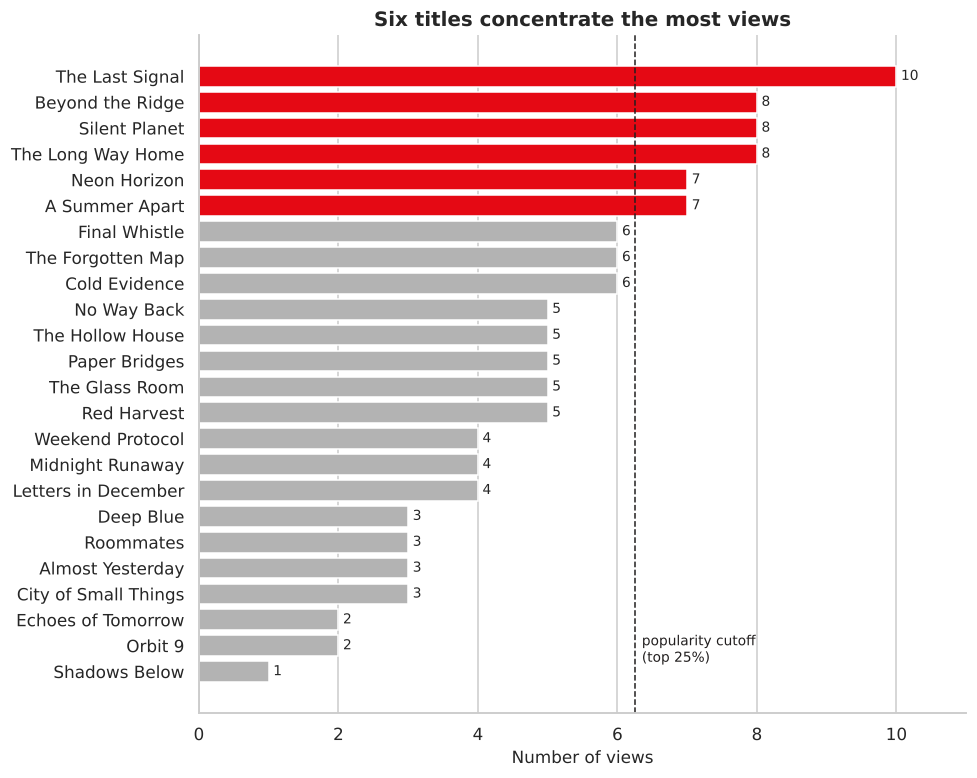

In [32]:
ranking = title_stats.sort_values("views")
colors = ranking["is_popular"].map({True: ACCENT, False: GREY})

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(ranking["title"], ranking["views"], color=colors)
ax.bar_label(bars, padding=3, fontsize=9)
ax.axvline(POPULAR_CUTOFF, color=DARK, linestyle="--", linewidth=1)
ax.text(POPULAR_CUTOFF + 0.1, 0.2, "popularity cutoff\n(top 25%)", fontsize=9, color=DARK, va="bottom")
ax.set_title("Six titles concentrate the most views")
ax.set_xlabel("Number of views")
ax.set_ylabel("")
ax.set_xlim(0, ranking["views"].max() + 1)
ax.grid(axis="y", visible=False)
save_fig(fig, "01_views_per_title.png")
plt.show()

**Reading the chart:** views are uneven across the catalog, from 1 to 10 per title. The six most-viewed titles (red) average 8 views, twice the 4 of the rest.

### 4.2 Longer titles get more views
Each dot is a title. The line shows the linear trend; the Spearman correlation is computed at title level.

Saved reports/figures/02_duration_vs_views.png


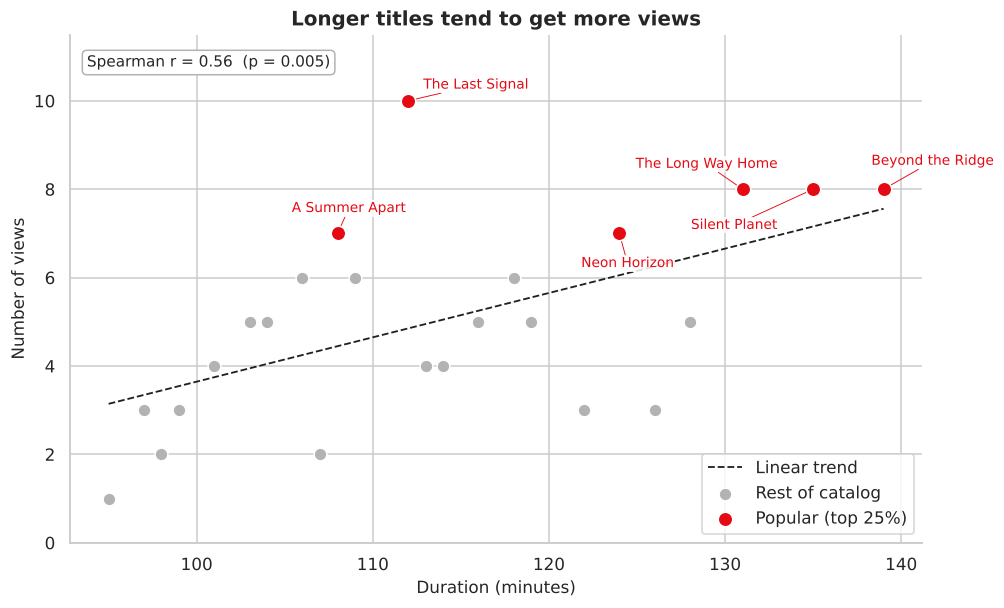

In [33]:
r, p = spearman(title_stats, "duration_min", "views")
slope, intercept = np.polyfit(title_stats["duration_min"], title_stats["views"], 1)
x_line = np.linspace(title_stats["duration_min"].min(), title_stats["duration_min"].max(), 50)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_line, slope * x_line + intercept, color=DARK, linestyle="--", linewidth=1.2, label="Linear trend")
rest = title_stats[~title_stats["is_popular"]]
pop = title_stats[title_stats["is_popular"]]
ax.scatter(rest["duration_min"], rest["views"], s=70, color=GREY, edgecolor="white", label="Rest of catalog", zorder=3)
ax.scatter(pop["duration_min"], pop["views"], s=90, color=ACCENT, edgecolor="white", label="Popular (top 25%)", zorder=4)

offsets = {  # manual label offsets (points) to avoid overlaps
    "The Last Signal": (10, 8), "Beyond the Ridge": (-8, 16), "Silent Planet": (-80, -26),
    "The Long Way Home": (-70, 14), "Neon Horizon": (-25, -22), "A Summer Apart": (-30, 14),
}
for _, row in pop.iterrows():
    ax.annotate(row["title"], (row["duration_min"], row["views"]), textcoords="offset points",
                xytext=offsets.get(row["title"], (6, 6)), fontsize=9, color=ACCENT, bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85),
                arrowprops=dict(arrowstyle="-", color=ACCENT, lw=0.6, shrinkA=0, shrinkB=4))

ax.text(0.02, 0.96, f"Spearman r = {r:.2f}  (p = {p:.3f})", transform=ax.transAxes,
        fontsize=10, va="top", bbox=dict(boxstyle="round", facecolor="white", edgecolor=GREY))
ax.set_title("Longer titles tend to get more views")
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Number of views")
ax.set_ylim(0, title_stats["views"].max() + 1.5)
ax.legend(loc="lower right", frameon=True)
save_fig(fig, "02_duration_vs_views.png")
plt.show()

**Reading the chart:** views rise with duration (r ≈ 0.56, p < 0.01). All six popular titles are 108 minutes or longer, and no title shorter than 108 minutes passed the popularity cutoff (maximum 5 views). It is a tendency, not a rule: some long titles (122 and 126 minutes) got only 3 views.

### 4.3 Genre: volume and satisfaction
Views are normalized per title because genres have different numbers of titles. The dashed lines show the catalog average.

Saved reports/figures/03_genre_views_and_ratings.png


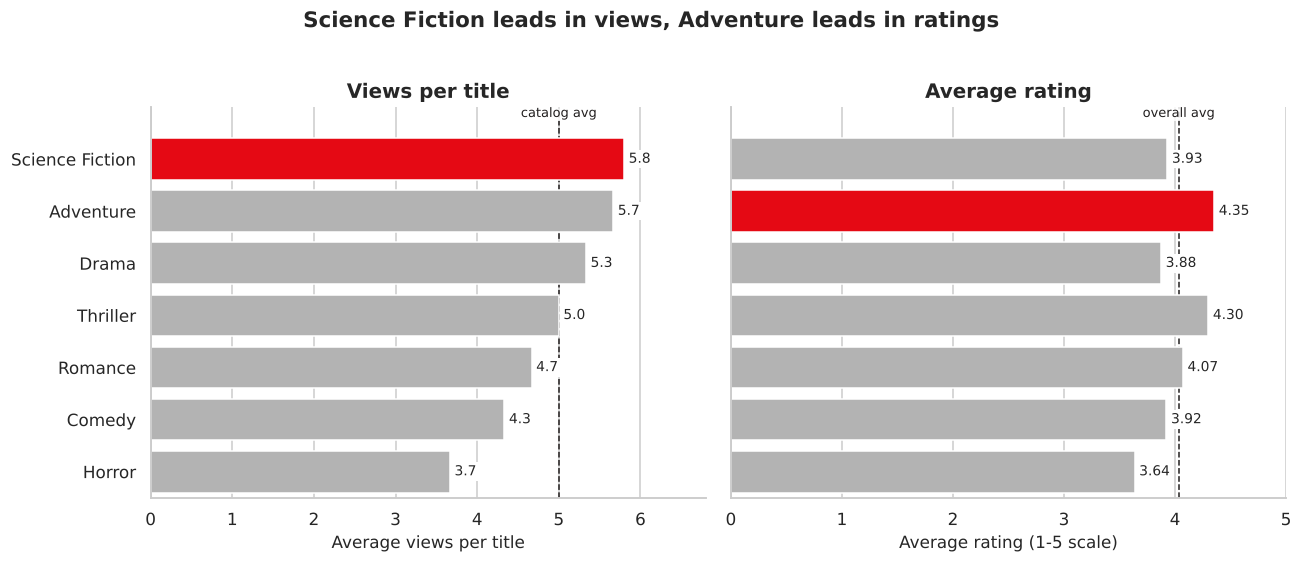

In [34]:
order = genre_stats.sort_values("views_per_title", ascending=False).index
data = genre_stats.loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

top_genre = data["genre"].iloc[0]
bar_colors = [ACCENT if g == top_genre else GREY for g in data["genre"]]
b1 = axes[0].barh(data["genre"], data["views_per_title"], color=bar_colors, zorder=2)
axes[0].axvline(title_stats["views"].mean(), color=DARK, linestyle="--", linewidth=1, zorder=1)
axes[0].bar_label(b1, fmt="%.1f", padding=3, fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
axes[0].text(title_stats["views"].mean(), -0.75, "catalog avg", fontsize=8.5, ha="center", va="bottom", color=DARK, bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85))
axes[0].set_title("Views per title")
axes[0].set_xlabel("Average views per title")
axes[0].set_ylabel("")
axes[0].set_ylim(len(data) - 0.5, -1.0)  # also reverses order: top = highest
axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(0, data["views_per_title"].max() + 1)

top_rated = data.loc[data["avg_rating"].idxmax(), "genre"]
bar_colors2 = [ACCENT if g == top_rated else GREY for g in data["genre"]]
b2 = axes[1].barh(data["genre"], data["avg_rating"], color=bar_colors2, zorder=2)
axes[1].axvline(merged["rating"].mean(), color=DARK, linestyle="--", linewidth=1, zorder=1)
axes[1].bar_label(b2, fmt="%.2f", padding=3, fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
axes[1].text(merged["rating"].mean(), -0.75, "overall avg", fontsize=8.5, ha="center", va="bottom", color=DARK, bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85))
axes[1].set_title("Average rating")
axes[1].set_xlabel("Average rating (1-5 scale)")
axes[1].set_xlim(0, 5)
axes[1].grid(axis="y", visible=False)

fig.suptitle("Science Fiction leads in views, Adventure leads in ratings", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "03_genre_views_and_ratings.png")
plt.show()

**Reading the chart:** Science Fiction has the most views per title (5.8), closely followed by Adventure (5.7), which also has the best average rating (4.35). Horror is last on both measures. Rating differences between genres are small compared with the 1–5 scale.

### 4.4 Popular does not mean better rated
Each dot is a title: views against its average rating.

Saved reports/figures/04_views_vs_rating.png


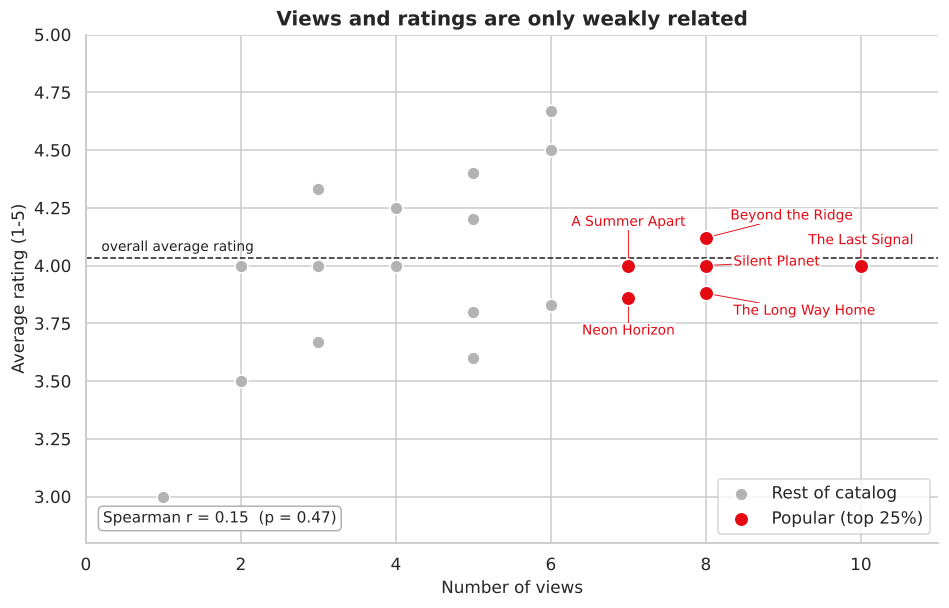

In [35]:
r2, p2 = spearman(title_stats, "views", "avg_rating")
rest = title_stats[~title_stats["is_popular"]]
pop = title_stats[title_stats["is_popular"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.axhline(merged["rating"].mean(), color=DARK, linestyle="--", linewidth=1)
ax.text(0.2, merged["rating"].mean() + 0.03, "overall average rating", fontsize=9, color=DARK, ha="left")
ax.scatter(rest["views"], rest["avg_rating"], s=70, color=GREY, edgecolor="white", label="Rest of catalog", zorder=3)
ax.scatter(pop["views"], pop["avg_rating"], s=90, color=ACCENT, edgecolor="white", label="Popular (top 25%)", zorder=4)

offsets = {  # (dx, dy, horizontal alignment)
    "The Last Signal": (0, 14, "center"), "Beyond the Ridge": (16, 12, "left"), "Silent Planet": (18, 0, "left"),
    "The Long Way Home": (18, -14, "left"), "Neon Horizon": (0, -24, "center"), "A Summer Apart": (0, 26, "center"),
}
for _, row in pop.iterrows():
    dx, dy, ha = offsets.get(row["title"], (6, 6, "left"))
    ax.annotate(row["title"], (row["views"], row["avg_rating"]), textcoords="offset points",
                xytext=(dx, dy), ha=ha, fontsize=9, color=ACCENT, bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85),
                arrowprops=dict(arrowstyle="-", color=ACCENT, lw=0.6, shrinkA=0, shrinkB=4))

ax.text(0.02, 0.04, f"Spearman r = {r2:.2f}  (p = {p2:.2f})", transform=ax.transAxes,
        fontsize=10, bbox=dict(boxstyle="round", facecolor="white", edgecolor=GREY))
ax.set_title("Views and ratings are only weakly related")
ax.set_xlabel("Number of views")
ax.set_ylabel("Average rating (1-5)")
ax.set_ylim(2.8, 5.0)
ax.set_xlim(0, title_stats["views"].max() + 1)
ax.legend(loc="lower right", frameon=True)
save_fig(fig, "04_views_vs_rating.png")
plt.show()

**Reading the chart:** all six popular titles sit close to the overall average rating (between 3.86 and 4.13), while the best-rated titles (4.3 to 4.7) have only 3 to 6 views. A title can attract many viewers without being the best rated. The relationship is weak (r ≈ 0.15) and not statistically clear.

### 4.5 Visualization summary

| Chart | Pattern | File |
|---|---|---|
| 4.1 Views per title | Views are concentrated: the top 6 titles average twice the views of the rest | `01_views_per_title.png` |
| 4.2 Duration vs views | Longer titles get more views (r ≈ 0.56) | `02_duration_vs_views.png` |
| 4.3 Genre | Science Fiction leads in views per title; Adventure in average rating | `03_genre_views_and_ratings.png` |
| 4.4 Views vs rating | Popularity and ratings are weakly related (r ≈ 0.15) | `04_views_vs_rating.png` |

## 5. Business Insights

The EDA found several patterns. Before turning them into business insights, this section runs four supporting checks:

1. Is the duration effect only a genre effect?
2. Does it hold if popularity is measured by reach (unique viewers) instead of views?
3. How much of the viewing volume is repeat viewing?
4. Which titles are well rated but under-watched?

### 5.1 Is the duration effect just a genre effect?

In [36]:
# Across genres: do genres with longer titles get more views per title?
genre_level = genre_stats[["avg_duration_min", "views_per_title"]].reset_index()
r_genre, p_genre = spearman(genre_level, "avg_duration_min", "views_per_title")
print(f"Across the {len(genre_level)} genres, average duration vs views per title: r = {r_genre}, p = {p_genre}")

# Within genres: compare each title with the average of its own genre
within_genre = pd.DataFrame({
    "duration_vs_genre_avg": title_stats["duration_min"] - title_stats.groupby("genre")["duration_min"].transform("mean"),
    "views_vs_genre_avg": title_stats["views"] - title_stats.groupby("genre")["views"].transform("mean"),
    "rating_vs_genre_avg": title_stats["avg_rating"] - title_stats.groupby("genre")["avg_rating"].transform("mean"),
})
r_wv, p_wv = spearman(within_genre, "duration_vs_genre_avg", "views_vs_genre_avg")
r_wr, p_wr = spearman(within_genre, "duration_vs_genre_avg", "rating_vs_genre_avg")
print("\nWithin genres (each title compared with its own genre average):")
print(f"  duration vs views:      r = {r_wv}, p = {p_wv}")
print(f"  duration vs avg rating: r = {r_wr}, p = {p_wr}")

# Short vs longer titles at viewing-record level
length_group = merged["duration_min"].apply(lambda minutes: "<= 105 min" if minutes <= 105 else "> 105 min")
short_vs_long = merged.groupby(length_group).agg(views=("rating", "size"), avg_rating=("rating", "mean"))
short_vs_long["share_of_views_%"] = (short_vs_long["views"] / len(merged) * 100).round(1)
short_vs_long["avg_rating"] = short_vs_long["avg_rating"].round(2)
print("\nViewing records by title length:")
display(short_vs_long)

Across the 7 genres, average duration vs views per title: r = 0.89, p = 0.007



Within genres (each title compared with its own genre average):
  duration vs views:      r = 0.55, p = 0.005
  duration vs avg rating: r = 0.42, p = 0.039

Viewing records by title length:


,views,avg_rating,share_of_views_%
duration_min,,,
<= 105 min,23,3.70,19.2
> 105 min,97,4.11,80.8


**Interpretation:** genres with longer titles do get more views per title, so duration and genre are indeed intertwined. However, inside each genre the longer titles still get more views and better ratings than the shorter titles of the same genre. Duration is therefore not just a proxy for genre: it keeps an association of its own.

### 5.2 Does the finding hold if popularity means reach instead of views?

In [37]:
r_views_viewers, p_views_viewers = spearman(title_stats, "views", "unique_viewers")
r_dur_viewers, p_dur_viewers = spearman(title_stats, "duration_min", "unique_viewers")

print(f"Views vs unique viewers:        r = {r_views_viewers}, p = {p_views_viewers}")
print(f"Duration vs unique viewers:     r = {r_dur_viewers}, p = {p_dur_viewers}")
print(f"Duration vs views (for comparison): r = {spearman(title_stats, 'duration_min', 'views')[0]}")

Views vs unique viewers:        r = 0.84, p = 0.0
Duration vs unique viewers:     r = 0.61, p = 0.001
Duration vs views (for comparison): r = 0.56


**Interpretation:** views and unique viewers move closely together, and duration is related to reach as well as to views. The main finding does not depend on counting repeat views.

### 5.3 Repeat viewing

In [38]:
# merged is sorted by watch_date, so the first record of each user-movie pair is the first watch
repeat_views = merged.assign(
    is_rewatch=merged.duplicated(subset=["user_id", "movie_id"]),
    is_popular=merged["movie_id"].map(title_stats.set_index("movie_id")["is_popular"]),
)

rewatch_summary = repeat_views.groupby("is_popular").agg(views=("is_rewatch", "size"), rewatches=("is_rewatch", "sum"))
rewatch_summary["rewatch_share_%"] = (rewatch_summary["rewatches"] / rewatch_summary["views"] * 100).round(1)
rewatch_summary.index = rewatch_summary.index.map({True: "Popular (top 25%)", False: "Rest of catalog"})
display(rewatch_summary)

print(f"Overall: {repeat_views['is_rewatch'].sum()} of {len(repeat_views)} records are re-watches "
      f"({repeat_views['is_rewatch'].mean() * 100:.1f}%)")

top_title = title_stats.sort_values("views", ascending=False).iloc[0]
print(f"Top title: '{top_title['title']}' has {top_title['views']} views from only {top_title['unique_viewers']} viewers")

,views,rewatches,rewatch_share_%
is_popular,,,
Rest of catalog,72,19,26.4
Popular (top 25%),48,21,43.8


Overall: 40 of 120 records are re-watches (33.3%)
Top title: 'The Last Signal' has 10 views from only 4 viewers


**Interpretation:** one third of all records are re-watches, and they are concentrated in popular titles (44% of their views vs 26% for the rest). The most-viewed title, *The Last Signal*, has 10 views from only 4 viewers. Popularity measured in views therefore mixes reach (how many people watch) with loyalty (how often they come back).

### 5.4 Well-rated but under-watched titles
Titles that are **not** popular but have an average rating of at least 4.25 (higher than the catalog average of about 4.0).

In [39]:
hidden_gems = (
    title_stats[(~title_stats["is_popular"]) & (title_stats["avg_rating"] >= 4.25)]
    .sort_values(["avg_rating", "views"], ascending=False)
    [["title", "genre", "duration_min", "views", "unique_viewers", "avg_rating"]]
    .reset_index(drop=True)
)
display(hidden_gems)
print(f"{len(hidden_gems)} of {len(title_stats)} titles; genres:", hidden_gems["genre"].value_counts().to_dict())

,title,genre,duration_min,views,unique_viewers,avg_rating
0,The Forgotten Map,Adventure,118,6,4,4.67
1,Cold Evidence,Thriller,109,6,4,4.50
2,No Way Back,Thriller,128,5,5,4.40
3,City of Small Things,Drama,122,3,2,4.33
4,Deep Blue,Adventure,126,3,2,4.33
5,Letters in December,Romance,114,4,2,4.25
6,Weekend Protocol,Comedy,113,4,3,4.25


7 of 24 titles; genres: {'Adventure': 2, 'Thriller': 2, 'Drama': 1, 'Romance': 1, 'Comedy': 1}


**Interpretation:** several titles are rated well above average without being among the most watched, with Thriller and Adventure well represented. Their averages rest on only 3 to 6 ratings each (from 2 to 5 viewers), so they are candidates to test, not proven hits.

### 5.5 Business insights

**Insight 1 – Duration is the strongest correlate of popularity.**
Longer titles get more views and better ratings (r ≈ 0.56 and 0.57), and the association remains inside each genre (r ≈ 0.55 for views). All six popular titles are 108 minutes or longer, and no title shorter than 108 minutes passed the popularity cutoff. Titles of up to 105 minutes receive 19% of the views and a lower average rating (3.70 vs 4.11 for longer titles).
*Business implication:* when choosing or commissioning content, runtimes of about 108 minutes or more perform better in this catalog. The data stops at 139 minutes, so it says nothing about even longer titles.

**Insight 2 – Science Fiction and Adventure are the strongest genres; Horror is the weakest.**
Science Fiction has the most views per title (5.8) and 3 of the 6 popular titles; Adventure is close (5.7) and has the best average rating (4.35). Horror is last on views per title (3.7) and on rating (3.64).
*Business implication:* Science Fiction and Adventure are the safest bets for volume and satisfaction. Genre and duration are intertwined (Horror and Comedy are also the shortest genres), so a longer Horror title may behave differently from the ones in this catalog.

**Insight 3 – Popularity is not the same as satisfaction, which creates a hidden-gem opportunity.**
Views and ratings are only weakly related (r ≈ 0.15), and popular titles are rated the same as the rest (3.98 vs 4.00). Seven titles are not popular but have ratings of 4.25 or more, led by *The Forgotten Map*, *Cold Evidence* and *No Way Back*.
*Business implication:* judging content by views alone hides quality. Combining views with ratings would identify well-liked titles that deserve more promotion or recommendation.

**Insight 4 – Popularity is driven by reach and amplified by repeat viewing.**
Views and unique viewers are strongly related (r ≈ 0.84), and one third of all records are re-watches, concentrated in popular titles (44% vs 26%). *The Last Signal* has 10 views but only 4 viewers.
*Business implication:* track reach and repeat viewing separately. A title with a loyal audience and a title with a broad audience are different assets, even if they have the same number of views.

**Insight 5 – Who made it explains little of popularity.**
Every director has 4 titles with similar results, and only 8 actors appear in the entire catalog, each in 5 to 7 titles. Neither director nor cast separates popular titles from the rest.
*Business implication:* with this data, director and cast should not be used as a main criterion for investment decisions; the characteristics of the title itself (length, genre) are more informative.

## 6. Conclusions

**Answer to the business question.** In this catalog, popular titles are characterized mainly by **longer duration** (all six are 108 minutes or more, averaging about 125 minutes) and by **genre** (Science Fiction accounts for half of them, with Adventure a close second in views per title and first in ratings). Director, cast and release year add little. Being popular does not mean being better rated, and a share of popularity comes from repeat viewing.

**What the analysis showed**
- Viewing volume is uneven: the top 6 titles average 8 views, twice the 4 of the rest.
- Duration is associated with both views and ratings, and the association holds inside genres.
- Science Fiction and Adventure lead; Horror trails on views and ratings.
- Views and ratings are only weakly related, so both metrics are needed.
- Reach and re-watching both contribute to popularity.

**Recommendations**
1. Favor content of roughly 108 minutes or more when selecting or producing titles, especially in Science Fiction and Adventure.
2. Use views **and** ratings together, and promote well-rated, under-watched titles (section 5.4).
3. Report reach (unique viewers) and repeat viewing separately from total views.
4. Do not rely on director or cast as the main criterion with this data.

**Limitations**
- **Very small sample:** 24 titles, 20 users and 120 records. The results are indications, not statistical proof, and testing many comparisons can produce coincidental patterns.
- **Views are counts of records**, without watch time or completion rate, so a "view" does not show whether the title was finished.
- **Ratings** come only from users who watched the title, and some titles have just 3 to 6 ratings.
- **Association is not causation:** longer titles may differ in other ways (budget, production, audience) that the data does not capture.
- **Re-watches count as views** (one third of the records); section 5.2 shows the duration finding does not depend on this.
- **Cast field is limited:** only 8 actors, always in pairs.
- **Time coverage:** 2026-01 is incomplete (data ends on January 6).

**Next steps**
- Repeat the analysis with a larger dataset of titles and viewers.
- Add watch time or completion rate as a stronger popularity measure.
- Test whether the duration effect appears when titles of the same genre are compared directly in a larger sample.

*All code, data and documentation: https://github.com/Italoomoura/Netflix_Project_Assignment*